In [35]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("final_cleaned_sales_data.csv")

sns.set_theme(style="whitegrid")

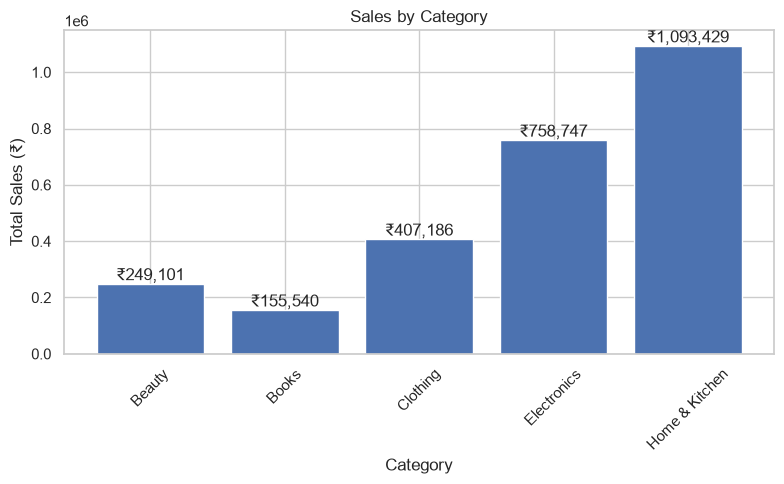

Highest Sales Category: Home & Kitchen
Highest Sales Amount: ₹ 1,093,429


In [50]:
# Calculate total sales for each category                #Which product category has the highest total sales
category_sales = df.groupby("category")["total"].sum()

# Create bar chart
plt.figure(figsize=(8, 5))
bars = plt.bar(category_sales.index, category_sales.values)

# Display sales amount above each bar
for bar in bars:
    value = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value,
        f"₹{value:,.0f}",
        ha="center",
        va="bottom"
    )

# Add chart title and labels
plt.title("Sales by Category")
plt.xlabel("Category")
plt.ylabel("Total Sales (₹)")

# Rotate category names
plt.xticks(rotation=45)

# Display chart
plt.tight_layout()
plt.show()

# Find highest sales category
print("Highest Sales Category:", category_sales.idxmax())
print("Highest Sales Amount: ₹", f"{category_sales.max():,.0f}")

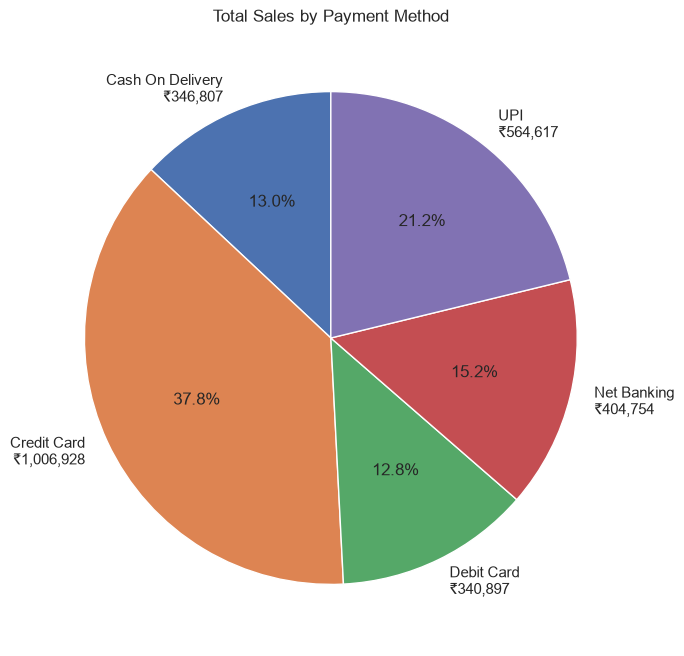

In [43]:
# Total sales amount for each payment method
payment = df.groupby("payment_method")["total"].sum()

plt.figure(figsize=(8, 8))

plt.pie(
    payment,
    labels=[f"{name}\n₹{amount:,.0f}" for name, amount in payment.items()],
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Total Sales by Payment Method")
plt.show()

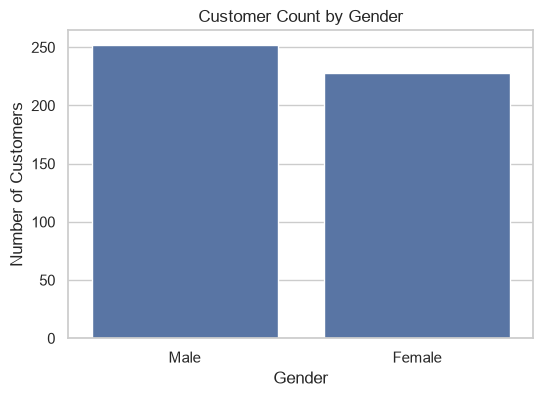

In [38]:
plt.figure(figsize=(6, 4))                  #How many customers belong to each gender?

sns.countplot(data=df, x="gender")

plt.title("Customer Count by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Customers")
plt.show()

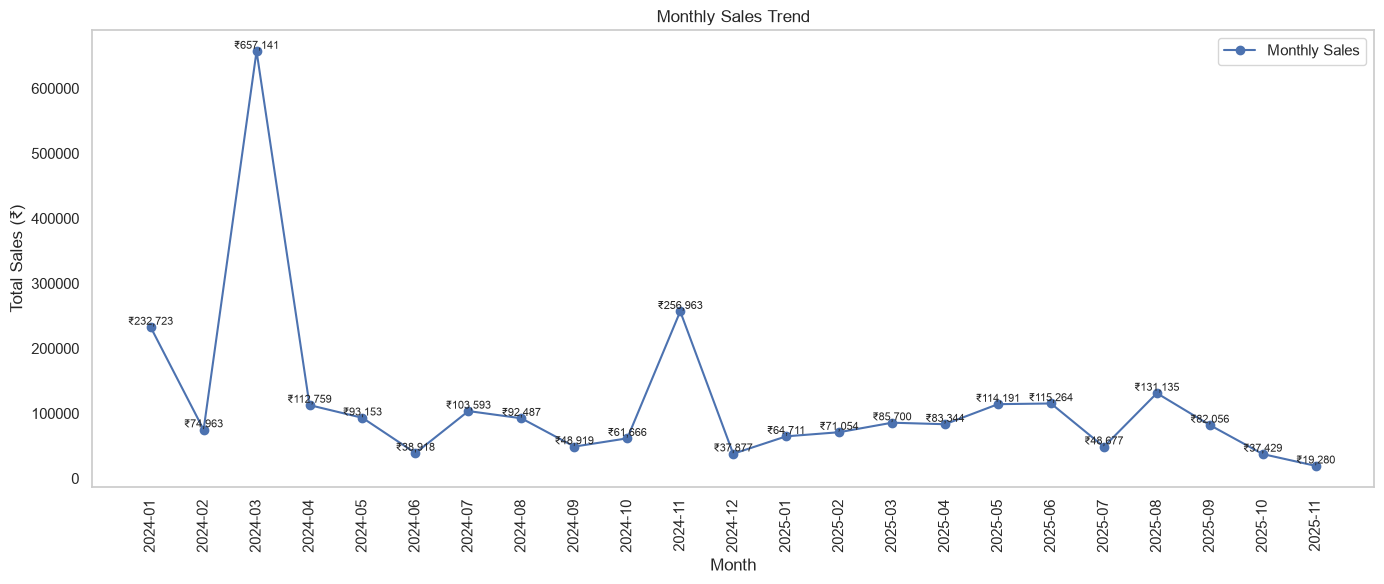

Highest Sales Month: 2024-03
Highest Monthly Sales: ₹ 657,141

YEARLY SALES DETAILS
order_date
2024    1811162
2025     852841
Name: total, dtype: int64

Highest Sales Year: 2024
Highest Yearly Sales: ₹ 1,811,162


In [45]:
df["order_date"] = pd.to_datetime(                           #Which month and year had the highest sales?
    df["order_date"], dayfirst=True, errors="coerce"
)

# Calculate monthly sales
monthly_sales = df.groupby(
    df["order_date"].dt.to_period("M")
)["total"].sum()

plt.figure(figsize=(14, 6))

# Draw line chart
plt.plot(
    monthly_sales.index.astype(str),
    monthly_sales.values,
    marker="o",
    label="Monthly Sales"
)

# Display every month's sales value
for x, y in enumerate(monthly_sales.values):
    plt.text(
        x, y,
        f"₹{y:,.0f}",
        ha="center",
        va="bottom",
        fontsize=8
    )

# Find highest sales month
highest_month = monthly_sales.idxmax()
highest_amount = monthly_sales.max()

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales (₹)")
plt.xticks(rotation=90)
plt.grid()
plt.legend()

plt.tight_layout()
plt.show()

# Calculate yearly sales
yearly_sales = df.groupby(
    df["order_date"].dt.year
)["total"].sum()

# Find highest sales year
highest_year = yearly_sales.idxmax()
highest_year_amount = yearly_sales.max()


print("Highest Sales Month:", highest_month)
print("Highest Monthly Sales: ₹", f"{highest_amount:,.0f}")

print("\nYEARLY SALES DETAILS")

print(yearly_sales)

print("\nHighest Sales Year:", highest_year)
print("Highest Yearly Sales: ₹", f"{highest_year_amount:,.0f}")

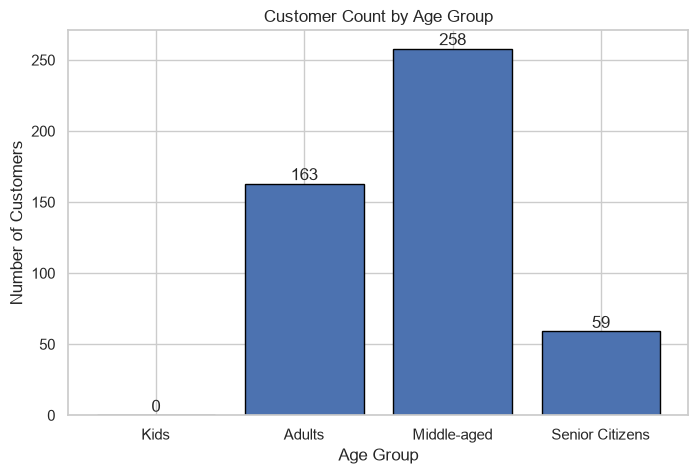

Highest Customer Age Group: Middle-aged
Number of Customers: 258


In [47]:
# Create age groups                                         #Which age group has the highest number of customers?
bins = [0, 17, 35, 59, 100]
labels = ["Kids", "Adults", "Middle-aged", "Senior Citizens"]

# Categorize customers based on age
df["age_group"] = pd.cut(
    df["age"],
    bins=bins,
    labels=labels
)

# Count customers in each age group
age_count = df["age_group"].value_counts().reindex(labels, fill_value=0)

# Create bar chart
plt.figure(figsize=(8, 5))

plt.bar(age_count.index, age_count.values, edgecolor="black")

# Display customer count above each bar
for x, y in enumerate(age_count.values):
    plt.text(x, y, str(y), ha="center", va="bottom")

# Add chart title and labels
plt.title("Customer Count by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Customers")

plt.show()

# Find the age group with the highest customers
print("Highest Customer Age Group:", age_count.idxmax())
print("Number of Customers:", age_count.max())

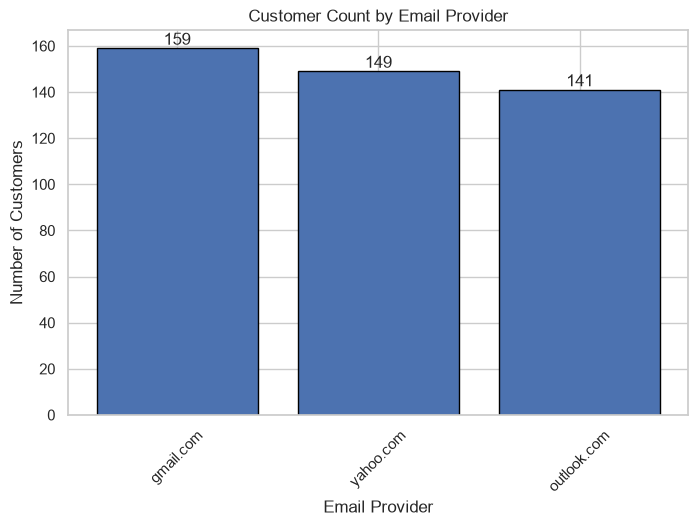

Most Used Email Provider: gmail.com
Number of Customers: 159


In [48]:
# Extract email provider from email column                         
df["email_provider"] = df["email"].str.split("@").str[-1].str.lower()

# Count customers using each email provider                  #Which email provider is most commonly used by customers?
email_count = df["email_provider"].value_counts()

# Create bar chart
plt.figure(figsize=(8, 5))

plt.bar(email_count.index, email_count.values, edgecolor="black")

# Display customer count above each bar
for x, y in enumerate(email_count.values):
    plt.text(x, y, str(y), ha="center", va="bottom")

# Add chart title and labels
plt.title("Customer Count by Email Provider")
plt.xlabel("Email Provider")
plt.ylabel("Number of Customers")

plt.xticks(rotation=45)
plt.show()

# Find the most commonly used email provider
print("Most Used Email Provider:", email_count.idxmax())
print("Number of Customers:", email_count.max())